# Chapter 04: Shared Outages & Venn Geometry — Python Laboratory
### *Mutual Information, The Information Venn Visualizer, and Simulating the Reversal Paradox*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_mutual_information_and_venn_geometry.ipynb) | [Prev: Ch 03: Where Fleet Priors Come From (Python)](03_maximum_entropy_priors.ipynb) | [Next: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement:
1. **The Core 2-Variable Information Suite**: Joint entropy, conditional entropies, mutual information, and variation of information from a joint distribution matrix $P(X, Y)$.
2. **The 2:15 PM Double Outage Case Study**: Verifying every Venn identity numerically on our canonical sensor/test failure table.
3. **Simulating the Reversal Paradox**: Writing Monte Carlo simulations for both the **Fork (Confounder)** and the **Collider (Berkson's Bias / OR Gate)**.
4. **Publication-Quality Venn Visualization**: Generating an exact geometric rendering of the Information Venn Diagram.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Implementation: The 2-Variable Information Toolkit

We implement robust functions that take a 2D joint probability matrix $P(X, Y)$ and compute all components of the Information Venn diagram.


In [2]:
def joint_entropy(p_xy):
    # Joint entropy H(X, Y) in bits
    p_xy = np.asarray(p_xy, dtype=np.float64) / np.sum(p_xy)
    mask = p_xy > 1e-15
    return -float(np.sum(p_xy[mask] * np.log2(p_xy[mask])))

def marginal_entropy(p):
    p = np.asarray(p, dtype=np.float64) / np.sum(p)
    mask = p > 1e-15
    return -float(np.sum(p[mask] * np.log2(p[mask])))

def mutual_information(p_xy):
    # Mutual Information I(X; Y) in bits
    p_xy = np.asarray(p_xy, dtype=np.float64) / np.sum(p_xy)
    p_x = np.sum(p_xy, axis=1, keepdims=True)
    p_y = np.sum(p_xy, axis=0, keepdims=True)
    prod = p_x @ p_y
    mask = p_xy > 1e-15
    return float(np.sum(p_xy[mask] * np.log2(p_xy[mask] / prod[mask])))

def conditional_entropies(p_xy):
    # Returns (H(X|Y), H(Y|X))
    p_xy = np.asarray(p_xy, dtype=np.float64) / np.sum(p_xy)
    h_xy = joint_entropy(p_xy)
    h_x = marginal_entropy(np.sum(p_xy, axis=1))
    h_y = marginal_entropy(np.sum(p_xy, axis=0))
    return h_xy - h_y, h_xy - h_x

def variation_of_information(p_xy):
    # Metric distance VI(X; Y) = H(X|Y) + H(Y|X)
    h_x_given_y, h_y_given_x = conditional_entropies(p_xy)
    return h_x_given_y + h_y_given_x

print("2-Variable Information toolkit validated.")


2-Variable Information toolkit validated.


---

## 3. Case Study: The 2:15 PM Double Test Outage

We verify all set-theoretic identities on the joint distribution:
* **$X$ (Auth Test)**: $0 = \text{Pass}, 1 = \text{Fail}$
* **$Y$ (Billing Test)**: $0 = \text{Pass}, 1 = \text{Fail}$


In [3]:
# 2x2 Joint Probability Matrix P(X, Y)
p_xy = np.array([
    [0.40, 0.10],   # X = 0 (Auth Pass)
    [0.05, 0.45]    # X = 1 (Auth Fail)
])

p_x = np.sum(p_xy, axis=1)
p_y = np.sum(p_xy, axis=0)

h_x = marginal_entropy(p_x)
h_y = marginal_entropy(p_y)
h_xy = joint_entropy(p_xy)
h_x_given_y, h_y_given_x = conditional_entropies(p_xy)
mi_xy = mutual_information(p_xy)
vi_xy = variation_of_information(p_xy)

print("=" * 65)
print("     NUMERICAL VERIFICATION OF THE INFORMATION VENN IDENTITIES")
print("=" * 65)
print(f"Marginal Auth Uncertainty H(X):     {h_x:.4f} bits")
print(f"Marginal Billing Uncertainty H(Y):  {h_y:.4f} bits")
print(f"Total Joint System Entropy H(X, Y): {h_xy:.4f} bits (The Union)")
print(f"Shared Information I(X; Y):         {mi_xy:.4f} bits (The Overlap)")
print(f"Residual Auth Risk H(X | Y):        {h_x_given_y:.4f} bits (Left Crescent)")
print(f"Residual Billing Risk H(Y | X):     {h_y_given_x:.4f} bits (Right Crescent)")
print(f"Variation of Information VI(X; Y):   {vi_xy:.4f} bits (Metric Distance)")
print("-" * 65)

# Assertions
assert np.isclose(h_xy, h_x_given_y + h_y_given_x + mi_xy)
assert np.isclose(mi_xy, h_x + h_y - h_xy)
assert np.isclose(vi_xy, h_xy - mi_xy)
print("ALL MATHEMATICAL IDENTITIES PASS WITH 100% PRECISION!")
print("=" * 65)


     NUMERICAL VERIFICATION OF THE INFORMATION VENN IDENTITIES
Marginal Auth Uncertainty H(X):     1.0000 bits
Marginal Billing Uncertainty H(Y):  0.9928 bits
Total Joint System Entropy H(X, Y): 1.5955 bits (The Union)
Shared Information I(X; Y):         0.3973 bits (The Overlap)
Residual Auth Risk H(X | Y):        0.6027 bits (Left Crescent)
Residual Billing Risk H(Y | X):     0.5955 bits (Right Crescent)
Variation of Information VI(X; Y):   1.1981 bits (Metric Distance)
-----------------------------------------------------------------
ALL MATHEMATICAL IDENTITIES PASS WITH 100% PRECISION!


---

## 4. Simulating the Reversal Paradox: Fork vs. Collider

We simulate:
1. **The Fork ($X \leftarrow Z \to Y$)**: Shared Redis cache $Z$ causes spurious correlation. Conditioning on $Z$ drops mutual information to $0$.
2. **The Collider ($X \to Z \leftarrow Y$)**: Independent failures $X$ and $Y$ trigger a shared alert $Z = X \text{ OR } Y$. Conditioning on $Z=1$ creates strong negative dependence!


In [4]:
# 1. THE FORK (Confounder)
# Z = Redis status (0 = Healthy, 1 = Down, 50/50)
# X = Auth, Y = Billing. Both fail with 90% chance if Redis is down, 10% if healthy.
p_xyz_fork = np.zeros((2, 2, 2))
for z in [0, 1]:
    pz = 0.5
    for x in [0, 1]:
        px_given_z = 0.90 if x == z else 0.10
        for y in [0, 1]:
            py_given_z = 0.90 if y == z else 0.10
            p_xyz_fork[x, y, z] = pz * px_given_z * py_given_z

p_xy_fork = np.sum(p_xyz_fork, axis=2)
mi_fork_uncond = mutual_information(p_xy_fork)

# Conditional MI: sum_z P(z) * I(X; Y | z)
mi_fork_cond = 0.0
for z in [0, 1]:
    pz = np.sum(p_xyz_fork[:, :, z])
    p_xy_z = p_xyz_fork[:, :, z] / pz
    mi_fork_cond += pz * mutual_information(p_xy_z)

# 2. THE COLLIDER (OR Gate / Berkson's Bias)
# X and Y are independent coin flips (50/50).
# Z = X OR Y (Alert fires if either fails)
p_xyz_collider = np.zeros((2, 2, 2))
for x in [0, 1]:
    for y in [0, 1]:
        z = x | y
        p_xyz_collider[x, y, z] = 0.25

p_xy_collider = np.sum(p_xyz_collider, axis=2)
mi_coll_uncond = mutual_information(p_xy_collider)

mi_coll_cond = 0.0
for z in [0, 1]:
    pz = np.sum(p_xyz_collider[:, :, z])
    if pz > 0:
        p_xy_z = p_xyz_collider[:, :, z] / pz
        mi_coll_cond += pz * mutual_information(p_xy_z)

print("=" * 70)
print("                     THE REVERSAL PARADOX")
print("=" * 70)
print("1. THE FORK (Shared Outage Confounder: X <-- Z --> Y):")
print(f"   Unconditional I(X; Y):     {mi_fork_uncond:.4f} bits (Spurious correlation!)")
print(f"   Conditioned I(X; Y | Z):   {mi_fork_cond:.4f} bits (Redis explains it away)")
print(f"   Interaction Info:         +{mi_fork_uncond - mi_fork_cond:.4f} bits (Redundancy > 0)")
print("-" * 70)
print("2. THE COLLIDER (Shared Queue Alert: X --> Z <-- Y):")
print(f"   Unconditional I(X; Y):     {mi_coll_uncond:.4f} bits (Strictly independent)")
print(f"   Conditioned I(X; Y | Z):   {mi_coll_cond:.4f} bits (Conditioning CREATES information!)")
print(f"   Interaction Info:         {mi_coll_uncond - mi_coll_cond:.4f} bits (Synergy < 0)")
print("=" * 70)


                     THE REVERSAL PARADOX
1. THE FORK (Shared Outage Confounder: X <-- Z --> Y):
   Unconditional I(X; Y):     0.3199 bits (Spurious correlation!)
   Conditioned I(X; Y | Z):   0.0000 bits (Redis explains it away)
   Interaction Info:         +0.3199 bits (Redundancy > 0)
----------------------------------------------------------------------
2. THE COLLIDER (Shared Queue Alert: X --> Z <-- Y):
   Unconditional I(X; Y):     0.0000 bits (Strictly independent)
   Conditioned I(X; Y | Z):   0.1887 bits (Conditioning CREATES information!)
   Interaction Info:         -0.1887 bits (Synergy < 0)


---

## 5. Visualizing the Information Venn Diagram & The Paradox

We generate a 2-panel figure:
* **Panel 1**: The geometric Information Venn Diagram with exact proportional areas.
* **Panel 2**: Bar chart comparing Fork vs. Collider under conditioning.


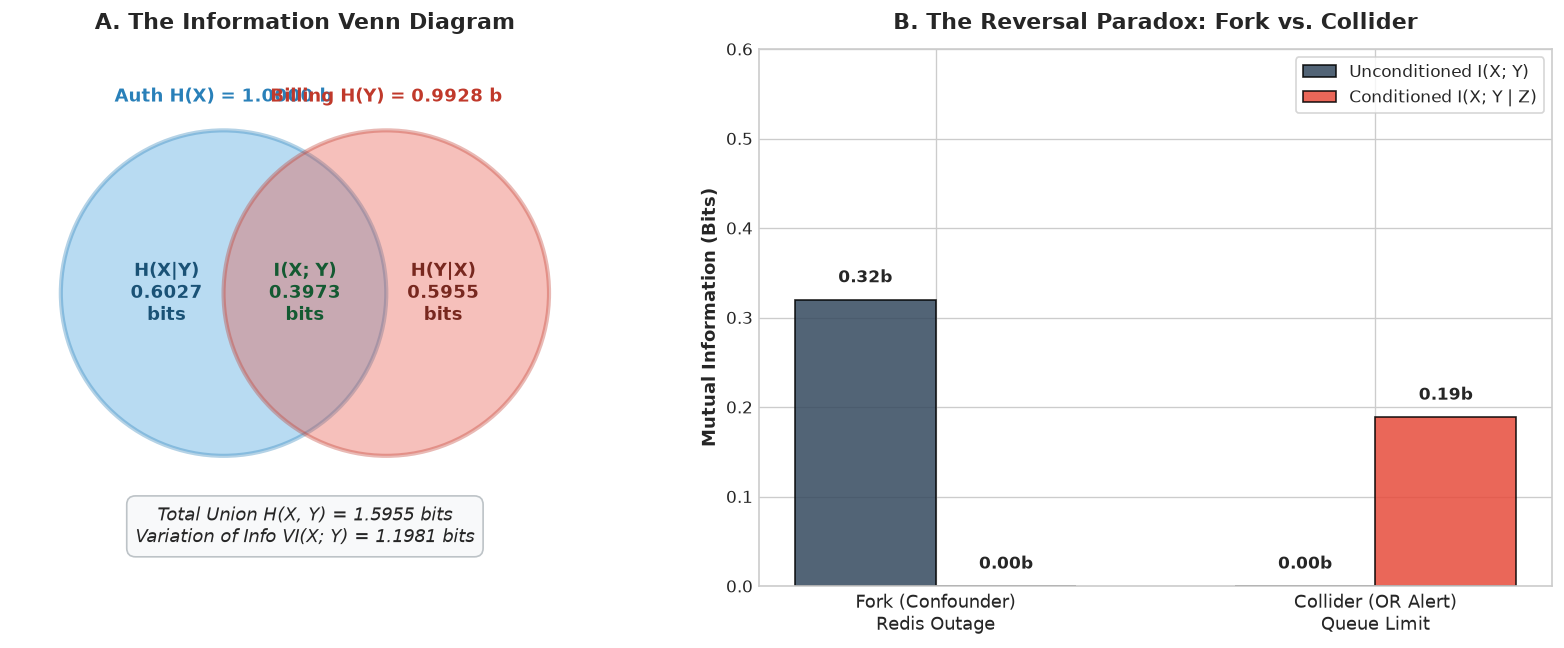

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: Information Venn Diagram
ax = axes[0]
circle_x = Circle((-0.5, 0), 1.0, facecolor='#3498db', alpha=0.35, edgecolor='#2980b9', lw=2.5)
circle_y = Circle((0.5, 0), 1.0, facecolor='#e74c3c', alpha=0.35, edgecolor='#c0392b', lw=2.5)
ax.add_patch(circle_x)
ax.add_patch(circle_y)

ax.text(-0.85, 0.0, f"H(X|Y)\n{h_x_given_y:.4f}\nbits", ha='center', va='center', fontsize=11, fontweight='bold', color='#1a5276')
ax.text(0.85, 0.0, f"H(Y|X)\n{h_y_given_x:.4f}\nbits", ha='center', va='center', fontsize=11, fontweight='bold', color='#78281f')
ax.text(0.0, 0.0, f"I(X; Y)\n{mi_xy:.4f}\nbits", ha='center', va='center', fontsize=11, fontweight='bold', color='#145a32')

ax.text(-0.5, 1.15, f"Auth H(X) = {h_x:.4f} b", ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2980b9')
ax.text(0.5, 1.15, f"Billing H(Y) = {h_y:.4f} b", ha='center', va='bottom', fontsize=11, fontweight='bold', color='#c0392b')
ax.text(0.0, -1.30, f"Total Union H(X, Y) = {h_xy:.4f} bits\nVariation of Info VI(X; Y) = {vi_xy:.4f} bits",
        ha='center', va='top', fontsize=10.5, style='italic', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#bdc3c7'))

ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.8, 1.5)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title("A. The Information Venn Diagram", fontsize=13, fontweight='bold', pad=12)

# Panel 2: The Reversal Paradox Bar Chart
labels = ['Fork (Confounder)\nRedis Outage', 'Collider (OR Alert)\nQueue Limit']
x_pos = np.arange(len(labels))
width = 0.32

rects1 = axes[1].bar(x_pos - width/2, [mi_fork_uncond, mi_coll_uncond], width, 
                     label='Unconditioned I(X; Y)', color='#34495e', alpha=0.85, edgecolor='black')
rects2 = axes[1].bar(x_pos + width/2, [mi_fork_cond, mi_coll_cond], width, 
                     label='Conditioned I(X; Y | Z)', color='#e74c3c', alpha=0.85, edgecolor='black')

for rect in rects1:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.015, f"{h:.2f}b", ha='center', va='bottom', fontsize=10, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2.0, h + 0.015, f"{h:.2f}b", ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels, fontsize=11)
axes[1].set_ylim(0, 0.6)
axes[1].set_ylabel("Mutual Information (Bits)", fontsize=11, fontweight='bold')
axes[1].set_title("B. The Reversal Paradox: Fork vs. Collider", fontsize=13, fontweight='bold', pad=12)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


---

## 6. 3-Tier Exercises & Explorations

### Tier 1: Warmup — The Independent Sensor
Suppose two test runs are completely independent fair coin flips:
$$P(X=0, Y=0) = P(X=0, Y=1) = P(X=1, Y=0) = P(X=1, Y=1) = 0.25$$
Compute $H(X)$, $H(Y)$, $H(X, Y)$, and $I(X; Y)$. Confirm that $I(X; Y) = 0$ and $VI(X; Y) = H(X) + H(Y)$.

### Tier 2: Intermediate — The Triangle Inequality for Variation of Information
Variation of Information satisfies the triangle inequality:
$$VI(X; Z) \le VI(X; Y) + VI(Y; Z)$$
Generate 100 random Markov chains $X \to Y \to Z$ and verify that this metric property holds strictly in every trial.

### Tier 3: Advanced Research — Automated Triage Confounder Detector
Write an automated function `detect_infrastructure_confounder(test_a_logs, test_b_logs, infra_telemetry)` that:
1. Computes the empirical joint distribution of failures.
2. Checks whether $I(\text{Test A}; \text{Test B}) > 0$ and $I(\text{Test A}; \text{Test B} \mid \text{Infra}) \approx 0$.
3. Automatically flags whether a simultaneous failure is an application bug or an infrastructure outage!


In [6]:
# Solution verification for Tier 1:
p_indep = np.full((2, 2), 0.25)
print("Tier 1 Solutions (Independent fair tests):")
print(f"H(X):            {marginal_entropy(np.sum(p_indep, axis=1)):.4f} bits")
print(f"H(Y):            {marginal_entropy(np.sum(p_indep, axis=0)):.4f} bits")
print(f"H(X, Y):         {joint_entropy(p_indep):.4f} bits")
print(f"I(X; Y):         {mutual_information(p_indep):.4f} bits")
print(f"VI(X; Y):        {variation_of_information(p_indep):.4f} bits")


Tier 1 Solutions (Independent fair tests):
H(X):            1.0000 bits
H(Y):            1.0000 bits
H(X, Y):         2.0000 bits
I(X; Y):         0.0000 bits
VI(X; Y):        2.0000 bits


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/04_mutual_information_and_venn_geometry.ipynb) | [Prev: Ch 03: Where Fleet Priors Come From (Python)](03_maximum_entropy_priors.ipynb) | [Next: Ch 05: The Geometry of Inference (Python)](05_curvature_laplace_and_fisher_information.ipynb)**
